# Supplementary Figure S5. Pair-type breakdown and controls for the score change of flagged base pairs after re-refinement and at higher resolution

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 600, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["rubric", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["RUBRIC", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_rubric.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_RUBRIC_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["rubric_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["rubric_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Panel setup
Time-reversal block


In [2]:
REDO = _json("validation/time_reversal_controls.json")["thresholds"][f"{CUT:g}"]
RES = _json("validation/time_reversal_resolved.json")

for tag, blk in (("PDB-REDO", REDO), ("re-solved", RES)):
    a = blk["asymmetry"]
    print(f"{tag:9s} units {blk['n_units']:4d} | "
          f"forward {blk['forward']['mean']:+6.2f} "
          f"[{blk['forward']['ci95'][0]:+.2f}, {blk['forward']['ci95'][1]:+.2f}] | "
          f"reverse {blk['reverse']['mean']:+6.2f} "
          f"[{blk['reverse']['ci95'][0]:+.2f}, {blk['reverse']['ci95'][1]:+.2f}] | "
          f"asymmetry {a['mean']:+6.2f} "
          f"[{a['ci95'][0]:+.2f}, {a['ci95'][1]:+.2f}]  P(<=0)={a['p_le_0']:.3f}")
print("\nimplied true improvement, re-solved: "
      f"{RES['implied_true_improvement']['mean']:+.2f} "
      f"[{RES['implied_true_improvement']['ci95'][0]:+.2f}, "
      f"{RES['implied_true_improvement']['ci95'][1]:+.2f}]")

REDO_PAIRS = pd.DataFrame(_json("validation/pdb_redo_pairs_comparison.json")["pairs"])

# Paired two-sided z-test on per-unit forward-minus-reverse changes (one value per
# structure or molecule, as in the other cluster-level tests of the paper).
import sys
from scipy.stats import norm
sys.path.insert(0, str(ROOT / "scripts" / "validation"))
from _rtm import per_unit

def paired_z(df, unit, a, b, cut=CUT):
    f = per_unit(df, unit, a, a, b, cut)
    r = per_unit(df, unit, b, b, a, cut)
    both = sorted(set(f.index) & set(r.index))
    d = (f[both] - r[both]).to_numpy()
    z = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
    return {"n": len(d), "z": float(z), "p": float(2 * norm.sf(abs(z)))}

def stars(p):
    return "****" if p < 1e-4 else "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 0.05 else "n.s."

Z_REDO = paired_z(REDO_PAIRS[["pdb_id", "orig_score", "redo_score"]].dropna(), "pdb_id", "orig_score", "redo_score")
Z_RES = paired_z(pd.read_csv(data_file("reference/resolved_again/resolve_pairs_matched.csv")), "rep", "score_w", "score_b")
for tag, zt in (("PDB-REDO", Z_REDO), ("higher-resolution", Z_RES)):
    print(f"{tag}: n = {zt['n']}, z = {zt['z']:.2f}, p = {zt['p']:.1e} ({stars(zt['p'])})")

PDB-REDO  units  227 | forward  +9.85 [+8.73, +10.94] | reverse  -0.57 [-1.38, +0.27] | asymmetry +10.41 [+8.84, +11.97]  P(<=0)=0.000
re-solved units   61 | forward +15.88 [+13.52, +18.20] | reverse +10.36 [+7.63, +13.31] | asymmetry  +5.52 [+2.36, +8.58]  P(<=0)=0.001

implied true improvement, re-solved: +2.76 [+1.18, +4.29]


PDB-REDO: n = 227, z = 12.89, p = 4.8e-38 (****)
higher-resolution: n = 61, z = 3.43, p = 6.1e-04 (***)


## Panel C
Mean score change, forward versus time-reversed, for the PDB-REDO and re-solved cohorts


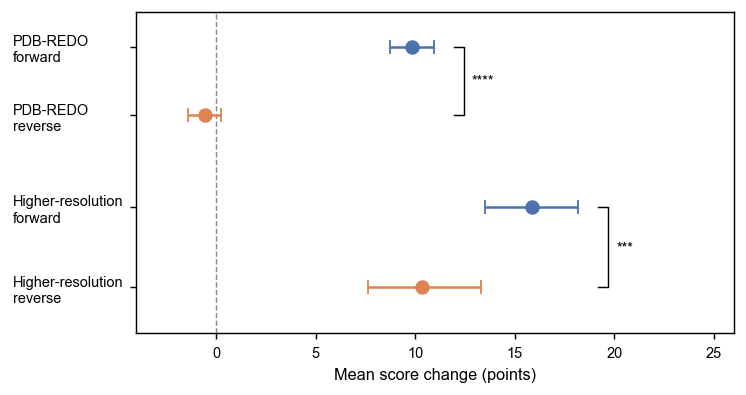

In [3]:
def left_align_yticklabels(ax):
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    labels = ax.get_yticklabels()
    for t in labels:
        t.set_horizontalalignment("left")
        t.set_multialignment("left")
    width = max(t.get_window_extent(renderer).width for t in labels) * 72 / fig.dpi
    ax.yaxis.set_tick_params(pad=width + plt.rcParams["ytick.major.pad"])


def draw_c(ax):
    rows = [("PDB-REDO\nforward", REDO["forward"], BLUE),
            ("PDB-REDO\nreverse", REDO["reverse"], ORANGE),
            ("Higher-resolution\nforward", RES["forward"], BLUE),
            ("Higher-resolution\nreverse", RES["reverse"], ORANGE)]
    ys = [4.2, 3.0, 1.4, 0.0]
    ax.axvline(0, color="0.55", lw=0.8, ls="--", zorder=1)
    for y, (_, d, colour) in zip(ys, rows):
        lo, hi = d["ci95"]
        ax.errorbar(d["mean"], y, xerr=[[d["mean"] - lo], [hi - d["mean"]]], fmt="o",
                    color=colour, ecolor=colour, capsize=4, markersize=7,
                    elinewidth=1.4, zorder=3)
    for (ya, yb), da, db, zt in ((ys[:2], rows[0][1], rows[1][1], Z_REDO),
                                 (ys[2:], rows[2][1], rows[3][1], Z_RES)):
        x = max(da["ci95"][1], db["ci95"][1]) + 1.0
        ax.plot([x, x + 0.5, x + 0.5, x], [ya, ya, yb, yb], color="black", lw=0.8, zorder=2)
        ax.text(x + 0.9, (ya + yb) / 2, stars(zt["p"]), ha="left", va="center", fontsize=8)
    ax.set_yticks(ys, [r[0] for r in rows], fontsize=8)
    ax.set_ylim(-0.8, 4.8)
    ax.set_xlim(-4, 26)
    ax.set_xlabel("Mean score change (points)")
    finish(ax)
    left_align_yticklabels(ax)


fig, ax = plt.subplots(figsize=(5.8, 3.1))
draw_c(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS5_C_time_reversed_delta.png")
plt.show()


## Panel D
The already-perfect structures: what re-refinement does when there is nothing to fix


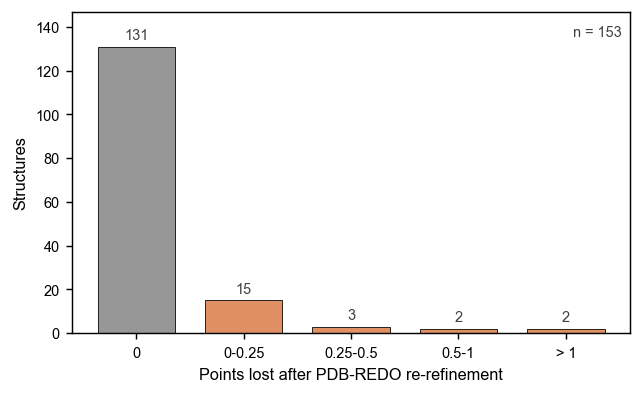

153 structures with every matched pair at 100 before re-refinement
  unchanged: 131 (86%) | mean change -0.053 | largest drop -2.12


In [4]:
STRUCT_100 = (REDO_PAIRS.groupby("pdb_id")
              .agg(before=("orig_score", "mean"), after=("redo_score", "mean"),
                   n=("orig_score", "size")))
STRUCT_100 = STRUCT_100[STRUCT_100.before >= 99.999]
LOSS_BINS = [-0.001, 0.001, 0.25, 0.5, 1.0, np.inf]
LOSS_LABELS = ["0", "0-0.25", "0.25-0.5", "0.5-1", "> 1"]

def draw_d(ax):
    loss = 100 - STRUCT_100.after
    counts = pd.cut(loss, bins=LOSS_BINS, labels=LOSS_LABELS).value_counts().reindex(LOSS_LABELS)
    ax.bar(np.arange(len(LOSS_LABELS)), counts.to_numpy(), width=0.72,
           color=[GREY] + [ORANGE] * (len(LOSS_LABELS) - 1), alpha=0.9,
           edgecolor="black", linewidth=0.5)
    for i, v in enumerate(counts.to_numpy()):
        ax.text(i, v + counts.max() * 0.015, f"{v}", ha="center", va="bottom",
                fontsize=8, color="0.25")
    ax.text(0.985, 0.96, f"n = {len(STRUCT_100)}", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color="0.25")
    ax.set_xticks(np.arange(len(LOSS_LABELS)), LOSS_LABELS)
    ax.set_ylim(0, counts.max() * 1.12)
    ax.set_xlabel("Points lost after PDB-REDO re-refinement")
    ax.set_ylabel("Structures")
    finish(ax)
    return counts


fig, ax = plt.subplots(figsize=(5.0, 3.1))
counts = draw_d(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS5_D_already_perfect.png")
plt.show()

loss = 100 - STRUCT_100.after
print(f"{len(STRUCT_100)} structures with every matched pair at 100 before re-refinement")
print(f"  unchanged: {int((loss < 0.001).sum())} ({(loss < 0.001).mean():.0%}) | "
      f"mean change {-loss.mean():+.3f} | largest drop {-loss.max():+.2f}")

## Panel setup
Canonical and noncanonical pairs under re-modelling

In [5]:
CANON = {"AU", "UA", "GC", "CG"}
GROUPS = ["canonical", "noncanonical"]

REDO_PAIRS["group"] = np.where((REDO_PAIRS.lw_class == "cWW") & REDO_PAIRS.bp_type.isin(CANON),
                               "canonical", "noncanonical")

RES_PAIRS = pd.read_csv(data_file("reference/resolved_again/resolve_pairs_matched.csv"))
_bp = RES_PAIRS.base1.astype(str) + RES_PAIRS.base2.astype(str)
RES_PAIRS["group"] = np.where((RES_PAIRS.lw_class == "cWW") & _bp.isin(CANON),
                              "canonical", "noncanonical")

for tag, df, before, after in (("PDB-REDO", REDO_PAIRS, "orig_score", "redo_score"),
                               ("re-solved", RES_PAIRS, "score_w", "score_b")):
    for gp in GROUPS:
        f = df[(df.group == gp) & (df[before] < CUT)]
        print(f"{tag:9s} {gp:12s} flagged {len(f):5,d}  median {f[before].median():5.1f} -> "
              f"{f[after].median():5.1f}  left Review tier {100 * (f[after] >= CUT).mean():3.0f}%")


def flagged_violins(ax, df, before, after, after_label):
    ax.axhspan(0, CUT, color="0.94", zorder=0)
    pos, gap = [], 0.0
    for gp in GROUPS:
        f = df[(df.group == gp) & (df[before] < CUT)]
        for k, (col, colour) in enumerate(((before, BLUE), (after, ORANGE))):
            x = gap + k * 0.9
            vp = ax.violinplot(f[col], positions=[x], widths=0.8, showextrema=False)
            for b in vp["bodies"]:
                b.set_facecolor(colour); b.set_edgecolor("0.25")
                b.set_linewidth(0.6); b.set_alpha(0.85)
            q1, med, q3 = np.percentile(f[col], [25, 50, 75])
            ax.vlines(x, q1, q3, color="0.15", lw=3, zorder=3)
            ax.scatter([x], [med], s=22, color="white", edgecolor="0.15", lw=0.8, zorder=4)
        pos.append(gap + 0.45)
        gap += 2.4
    ax.set_xticks(pos)
    ax.set_xticklabels(["Canonical", "Non-canonical"], fontsize=9)
    ax.set_ylim(14, 102)
    ax.set_yticks([20, 40, 60, 80, 100])
    ax.set_ylabel("Base-pair score")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE),
                       plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
              labels=["original", after_label], loc="lower right",
              borderaxespad=0.1, labelspacing=0.25)
    finish(ax)


PDB-REDO  canonical    flagged 2,139  median  71.3 ->  90.0  left Review tier  69%
PDB-REDO  noncanonical flagged   272  median  74.9 ->  77.4  left Review tier  40%
re-solved canonical    flagged   823  median  72.5 ->  99.9  left Review tier  82%
re-solved noncanonical flagged   249  median  75.0 ->  93.7  left Review tier  73%


## Panel A
Flagged canonical and noncanonical pairs before and after PDB-REDO re-refinement

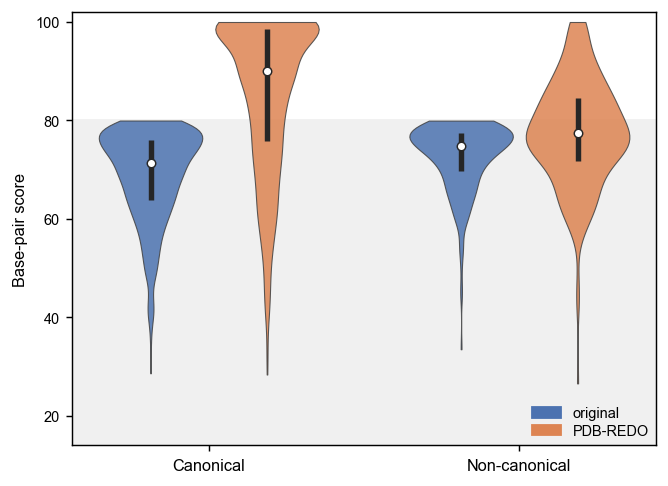

In [6]:
def draw_a(ax):
    flagged_violins(ax, REDO_PAIRS, "orig_score", "redo_score", "PDB-REDO")


fig, ax = plt.subplots(figsize=(5.2, 3.8))
draw_a(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS5_A_redo_canonical_noncanonical.png")
plt.show()


## Panel B
Flagged canonical and noncanonical pairs before and after re-solving from better data

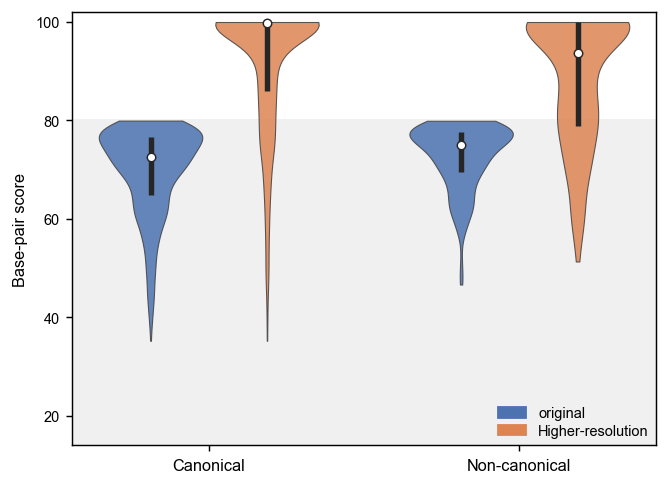

In [7]:
def draw_b(ax):
    flagged_violins(ax, RES_PAIRS, "score_w", "score_b", "Higher-resolution")


fig, ax = plt.subplots(figsize=(5.2, 3.8))
draw_b(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS5_B_resolved_canonical_noncanonical.png")
plt.show()


## Combined figure


text scaled x1.07: 7 pt prints at 7.1 pt at page width


axis titles print at 8.5 pt and panel letters at 12.0 pt (7.11 in saved, shown at 6.73 in)


text 7.0 pt, axis titles 8.5 pt, panel letters 12.0 pt at 6.73 in (7.11 in saved)


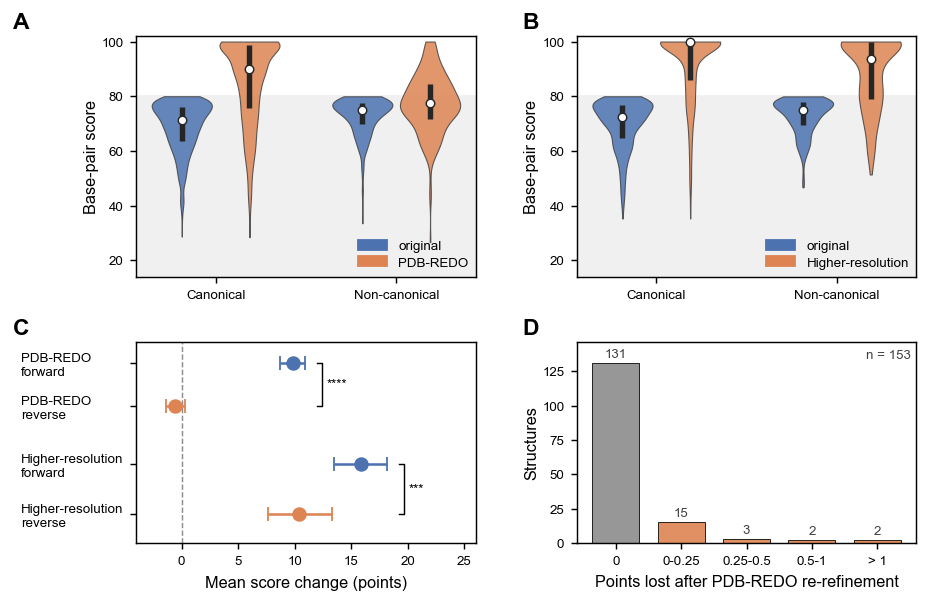

In [8]:
LABEL_IN, COL_GAP, ROW_GAP = 0.66, 0.78, 0.50
COL_W = (6.66 - LABEL_IN - COL_GAP) / 2
X1, X2 = LABEL_IN, LABEL_IN + COL_W + COL_GAP
H_AB, H_CD = 1.85, 1.55          # A, B: pair-type violins; C, D: controls
Y_AB = 0.25
Y_CD = Y_AB + H_AB + ROW_GAP
FIG_W, FIG_H = X2 + COL_W + 0.06, Y_CD + H_CD + 0.40
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
ax_a = fig.add_axes(inch(X1, Y_AB, COL_W, H_AB)); ax_b = fig.add_axes(inch(X2, Y_AB, COL_W, H_AB))
ax_c = fig.add_axes(inch(X1, Y_CD, COL_W, H_CD)); ax_d = fig.add_axes(inch(X2, Y_CD, COL_W, H_CD))
draw_a(ax_a); draw_b(ax_b); draw_c(ax_c); draw_d(ax_d)
for _ax in (ax_a, ax_b, ax_d):
    _ax.yaxis.labelpad = 1.5                      # y title close to the tick numbers
fig.canvas.draw()
_r = fig.canvas.get_renderer(); _inv = fig.transFigure.inverted()
_x_left = min(a.get_tightbbox(_r).transformed(_inv).x0 for a in (ax_a, ax_c))
for ax, s in ((ax_a, "A"), (ax_b, "B"), (ax_c, "C"), (ax_d, "D")):
    x = _x_left if s in "AC" else ax.get_tightbbox(_r).transformed(_inv).x0
    y = max(ax.get_position().y1, ax.get_tightbbox(_r).transformed(_inv).y1)
    fig.text(x, y + 0.006, s, fontsize=12, fontweight="bold", ha="left", va="bottom")
import matplotlib.text as mtext
for _t in fig.findobj(mtext.Text):
    if _t in fig.texts and _t.get_fontweight() in ("bold", 700) and len(_t.get_text().strip()) <= 2:
        _t.set_fontsize(12)
    else:
        _t.set_fontsize(7)
enlarge_axis_labels(fig)
for _ax in fig.axes:
    _ax.xaxis.label.set_fontsize(7)
    _ax.yaxis.label.set_fontsize(7)
import matplotlib.text as _mtext
def _print_scale(fig, page_in=6.73, pad=0.08):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    return max(1.0, (bb.width + 2 * pad) / page_in)
fig.canvas.draw()
_texts = [t for t in fig.findobj(_mtext.Text) if t.get_text().strip()]
_base = {t: t.get_fontsize() for t in _texts}
_s = 1.0
for _ in range(6):
    _need = _print_scale(fig)
    if _s >= _need - 1e-3:
        break
    _s = _need * 1.01
    for _t in _texts:
        _t.set_fontsize(_base[_t] * _s)
print(f"text scaled x{_s:.2f}: 7 pt prints at {7 * _s / _print_scale(fig):.1f} pt "
      f"at page width")
left_align_yticklabels(ax_c)
def _set_print_sizes(fig, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    letters = [t for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for ax in fig.axes:
            for lab in (ax.xaxis.label, ax.yaxis.label):
                if lab.get_text().strip():
                    lab.set_fontsize(axis_pt * shrink)
        for t in letters:
            t.set_fontsize(letter_pt * shrink)
    print(f"axis titles print at {axis_pt} pt and panel letters at {letter_pt} pt "
          f"({bb.width + 2 * pad:.2f} in saved, shown at {min(page_in, bb.width + 2 * pad):.2f} in)")


_set_print_sizes(fig)
for _ax in (ax_a, ax_b):
    for _t in _ax.get_xticklabels():
        _t.set_fontsize(_ax.yaxis.label.get_fontsize())

def _enforce_print_spec(fig, text_pt=7.0, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    """Ticks and other text at text_pt, axis titles at axis_pt, panel letters at letter_pt, as printed at page_in wide."""
    import matplotlib.text as mtext
    axis = {id(lab) for ax in fig.axes for lab in (ax.xaxis.label, ax.yaxis.label)}
    letters = {id(t) for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)}
    texts = [t for t in fig.findobj(mtext.Text) if t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for t in texts:
            t.set_fontsize((letter_pt if id(t) in letters else axis_pt if id(t) in axis else text_pt) * shrink)
    print(f"text {text_pt} pt, axis titles {axis_pt} pt, panel letters {letter_pt} pt at {page_in} in "
          f"({bb.width + 2 * pad:.2f} in saved)")


_enforce_print_spec(fig)
save(fig, "figures/supplemental/figS5.png")
plt.show()
